# 03 — CLIP Retrieval Evaluation

## Purpose of this notebook

This notebook performs the **systematic quantitative evaluation of the CLIP image-retrieval baseline**.

The previous notebooks established how architectural images are represented by CLIP and how nearest-neighbor retrieval works. Here we move from illustrative examples to the full dataset and ask:

> **How often does CLIP retrieve an image carrying the same architectural-style label as the query, and what kinds of cross-style retrievals occur when it does not?**

This notebook has two related roles in our article.

First, it establishes the conventional **exact-label retrieval baseline** using Precision@K. This gives a reproducible benchmark under the standard assumption that a retrieval is relevant only when the retrieved image has the same dataset label as the query.

Second, it records CLIP's **cross-label top-1 retrievals**. Those retrievals become especially important later because our paper asks whether an apparent label error may nevertheless represent meaningful architectural similarity.

The notebook first examines the full 25-style collection, then removes Achaemenid and Ancient Egyptian architecture to create the 23-style domain used for the practical house-search study.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

metadata = pd.read_csv("architecture_metadata.csv")
embeddings = np.load("clip_image_embeddings.npy")

print(metadata.shape)
print(embeddings.shape)

assert len(metadata) == len(embeddings)
print("Everything aligned!")

(10113, 3)
(10113, 512)
Everything aligned!


## Compute top-1 exact-label agreement over the full dataset

Every image is used once as a query. For each query, CLIP retrieves the nearest other image in the embedding space.

The query image itself must be excluded; otherwise its cosine similarity with itself would trivially dominate the ranking. Setting the self-similarity to negative infinity guarantees that the selected top-1 result is another image.

`top1_correct` records whether the retrieved image's dataset style label equals the query image's style label.

### Interpretation

The mean of this Boolean array is equivalent to **Precision@1 under exact-label relevance**.

This is a deliberately strict criterion. It answers:

> "Did the nearest retrieved image carry exactly the same dataset style label?"

It does *not* answer:

> "Was the retrieved building architecturally similar?"

That distinction motivates the later architectural-relevance analysis.


In [2]:
styles = metadata["style"].to_numpy()
n = len(embeddings)

# Store whether the top-1 result was correct for every query
top1_correct = np.zeros(n, dtype=bool)

batch_size = 256

for start in range(0, n, batch_size):
    end = min(start + batch_size, n)

    query_batch = embeddings[start:end]

    # Compare this batch with the entire database
    similarities = query_batch @ embeddings.T

    # Prevent each image from retrieving itself
    rows = np.arange(end - start)
    cols = np.arange(start, end)
    similarities[rows, cols] = -np.inf

    # Find the single most similar image
    top1_indices = np.argmax(similarities, axis=1)

    # Does its style match the query style?
    query_styles = styles[start:end]
    retrieved_styles = styles[top1_indices]

    top1_correct[start:end] = (query_styles == retrieved_styles)

print("Overall P@1:", top1_correct.mean())

Overall P@1: 0.7522001384356769


## Identify queries whose top-1 retrieval has a different style label

This pass collects the queries for which the nearest CLIP neighbor belongs to a different nominal architectural class.


In [3]:
different_queries = []

for start in range(0, n, batch_size):
    end = min(start + batch_size, n)

    query_batch = embeddings[start:end]
    similarities = query_batch @ embeddings.T

    # Remove self-matches
    rows = np.arange(end - start)
    cols = np.arange(start, end)
    similarities[rows, cols] = -np.inf

    # Method 1: argmax
    top1_argmax = np.argmax(similarities, axis=1)

    # Method 2: same sorting method used in our original baseline
    ranked_indices = np.argsort(similarities, axis=1)[:, ::-1]
    top1_sort = ranked_indices[:, 0]

    # Find queries where the two methods choose different images
    for i in range(end - start):
        if top1_argmax[i] != top1_sort[i]:
            query_id = start + i

            different_queries.append({
                "query_id": query_id,
                "query_style": styles[query_id],
                "argmax_id": top1_argmax[i],
                "argmax_style": styles[top1_argmax[i]],
                "argmax_similarity": similarities[i, top1_argmax[i]],
                "sort_id": top1_sort[i],
                "sort_style": styles[top1_sort[i]],
                "sort_similarity": similarities[i, top1_sort[i]]
            })


print("Number of different top-1 choices:", len(different_queries))

Number of different top-1 choices: 125


## Recompute top-1 agreement using one consistent ranking procedure

This cell deliberately repeats the top-1 calculation using the original retrieval procedure so that subsequent analyses rely on one consistent definition of the nearest neighbor.

Reproducibility matters here because later confusion counts and cross-style analyses depend on the exact top-1 index chosen for every query.

The output should agree with the earlier top-1 calculation. Any discrepancy would signal an implementation inconsistency that should be resolved before proceeding.


In [4]:
# Use the original ranking procedure consistently
top1_correct = np.zeros(n, dtype=bool)

for start in range(0, n, batch_size):
    end = min(start + batch_size, n)

    query_batch = embeddings[start:end]
    similarities = query_batch @ embeddings.T

    # Remove self-matches
    rows = np.arange(end - start)
    cols = np.arange(start, end)
    similarities[rows, cols] = -np.inf

    # Same ranking procedure as our original baseline
    ranked_indices = np.argsort(similarities, axis=1)[:, ::-1]
    top1_indices = ranked_indices[:, 0]

    top1_correct[start:end] = (
        styles[start:end] == styles[top1_indices]
    )

# Calculate P@1 separately for each style
style_results = []

for style in np.unique(styles):
    mask = (styles == style)

    style_results.append({
        "style": style,
        "n_images": mask.sum(),
        "P@1": top1_correct[mask].mean()
    })

style_results = pd.DataFrame(style_results)
style_results = style_results.sort_values("P@1", ascending=False)

style_results

,style,n_images,P@1
3,Ancient Egyptian architecture,406,0.970443
0,Achaemenid architecture,392,0.936224
5,Art Nouveau architecture,615,0.894309
18,Novelty architecture,382,0.890052
12,Deconstructivism,335,0.886567
15,Gothic architecture,331,0.854985
23,Russian Revival architecture,352,0.803977
10,Chicago school architecture,278,0.784173
22,Romanesque architecture,301,0.767442
21,Queen Anne architecture,720,0.752778


## Store the top-1 retrieved image index for every query

Rather than storing only whether a retrieval is an exact-label match, we now preserve **which image was actually retrieved**.

`all_top1_indices[i]` gives the dataset row/index of the nearest non-self image retrieved for query `i`.

This is an important transition. A Boolean success/failure variable is sufficient for P@1, but understanding retrieval behavior requires the identity and style of the retrieved neighbor.

These stored indices allow us to construct confusion tables, inspect recurring cross-style relationships, and later preserve query–retrieval pairs for architectural analysis.


In [5]:
# Store the top-1 retrieved image ID for every query
all_top1_indices = np.zeros(n, dtype=int)

for start in range(0, n, batch_size):
    end = min(start + batch_size, n)

    query_batch = embeddings[start:end]

    # Compare each query with the entire database
    similarities = query_batch @ embeddings.T

    # Prevent self-retrieval
    rows = np.arange(end - start)
    cols = np.arange(start, end)
    similarities[rows, cols] = -np.inf

    # Rank using the same method as our original baseline
    ranked_indices = np.argsort(similarities, axis=1)[:, ::-1]

    # Save the top-1 retrieved image ID
    all_top1_indices[start:end] = ranked_indices[:, 0]

print("Saved top-1 results for:", len(all_top1_indices), "queries")

Saved top-1 results for: 10113 queries


## Convert retrieved image indices into retrieved style labels

The stored nearest-neighbor indices are mapped back to their dataset style labels.

The variable name `predicted_styles` is convenient but should be interpreted carefully: CLIP did not directly output a style prediction. The "predicted" style is simply the existing label of the image that CLIP retrieved at rank 1.

The reported overall P@1 is therefore the fraction of queries whose nearest retrieved image shares the query's exact dataset label.


In [6]:
predicted_styles = styles[all_top1_indices]

print("Overall P@1:",
      np.mean(predicted_styles == styles))

Overall P@1: 0.7522990210619994


## Construct a top-1 style-confusion table

This cross-tabulation counts how often each query style retrieves each top-1 style.

Rows correspond to the **query's dataset style**, while columns correspond to the **dataset style of the retrieved nearest-neighbor image**.

The diagonal contains exact-label retrievals. Off-diagonal cells reveal systematic cross-style retrieval relationships.

### Why this table is useful

A single overall P@1 value hides structure. Two systems could have the same P@1 while making very different kinds of cross-label retrievals. The confusion table helps reveal whether CLIP repeatedly places particular architectural categories near one another.

However, frequency alone does not tell us whether an off-diagonal relationship is architecturally sensible. That question requires the independent architectural-similarity analysis developed later.


In [7]:
# Create a table of true style vs retrieved top-1 style
confusion_table = pd.crosstab(
    pd.Series(styles, name="True style"),
    pd.Series(predicted_styles, name="Retrieved style")
)

confusion_table

Retrieved style,Achaemenid architecture,American Foursquare architecture,American craftsman style,Ancient Egyptian architecture,Art Deco architecture,Art Nouveau architecture,Baroque architecture,Bauhaus architecture,Beaux-Arts architecture,Byzantine architecture,...,Gothic architecture,Greek Revival architecture,International style,Novelty architecture,Palladian architecture,Postmodern architecture,Queen Anne architecture,Romanesque architecture,Russian Revival architecture,Tudor Revival architecture
True style,,,,,,,,,,,,,,,,,,,,,
Achaemenid architecture,367,0,0,18,1,0,1,0,0,1,...,0,0,0,1,2,0,0,0,0,0
American Foursquare architecture,0,199,53,0,0,0,0,0,0,0,...,0,15,0,0,0,0,68,0,0,10
American craftsman style,0,34,229,0,0,0,0,0,0,0,...,0,11,1,0,0,0,52,0,0,22
Ancient Egyptian architecture,11,0,0,394,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Art Deco architecture,0,0,3,0,419,35,3,16,18,0,...,1,2,19,0,2,11,1,0,3,2
Art Nouveau architecture,0,1,1,0,21,550,8,1,12,2,...,0,0,0,0,2,0,1,2,5,1
Baroque architecture,0,0,0,0,0,26,341,0,13,10,...,4,5,0,0,8,0,0,9,16,0
Bauhaus architecture,0,0,0,0,11,6,1,216,3,0,...,0,0,57,0,1,5,1,0,0,2
Beaux-Arts architecture,1,0,1,1,9,22,7,3,284,1,...,1,19,1,0,16,1,7,0,0,3


## Extract the most frequent cross-style retrievals for each query style

For every true/query style, this cell removes the diagonal same-style count and identifies the most common alternative styles retrieved by CLIP.

This produces an interpretable summary of the large confusion matrix.

These frequent pairings can suggest hypotheses—for example, whether visually or historically related styles tend to occupy nearby regions of CLIP space—but they should not yet be treated as proof of architectural relatedness.

We later test that idea quantitatively rather than relying only on intuitive examples.


In [8]:
top_confusions = []

for true_style in confusion_table.index:

    # Get this style's row
    row = confusion_table.loc[true_style].copy()

    # Remove the correct same-style result
    row = row.drop(true_style)

    # Find the 3 most common wrong styles
    top3 = row.sort_values(ascending=False).head(3)

    for retrieved_style, count in top3.items():
        top_confusions.append({
            "True style": true_style,
            "Confused with": retrieved_style,
            "Count": count
        })

top_confusions = pd.DataFrame(top_confusions)

top_confusions.to_csv(
    "clip_top_style_confusions.csv",
    index=False
)

print("Saved clip_top_style_confusions.csv")

Saved clip_top_style_confusions.csv


## Save per-style precision results

The per-style results are exported to `clip_precision_by_style.csv`.

Saving intermediate results is important for reproducibility and for separating expensive retrieval computation from later analysis and figure generation. It also creates a stable artifact that can be used for paper tables without rerunning the entire notebook.

This file represents conventional label-based performance by architectural style.


In [9]:
style_results.to_csv(
    "clip_precision_by_style.csv",
    index=False
)

print("Saved clip_precision_by_style.csv")

Saved clip_precision_by_style.csv


## Count same-style and cross-style top-1 retrievals

This cell summarizes the full-dataset top-1 outcomes into two groups:

- **same-style retrievals** — query and retrieved image share the exact dataset label;
- **cross-style retrievals** — their dataset labels differ.

The cross-style group is the set that conventional P@1 assigns zero credit.

This count is conceptually important because later Paper-One analysis asks how much architectural relevance may be hidden inside this nominal error set.


In [10]:
cross_style_mask = predicted_styles != styles
print("Total queries:", len(styles))
print("Same-style:", np.sum(predicted_styles == styles))
print("Cross-style:", np.sum(cross_style_mask))

Total queries: 10113
Same-style: 7608
Cross-style: 2505


## Save the individual cross-style query–retrieval pairs

This table preserves each cross-style event at the image level, including the query identity, query style, retrieved image identity, retrieved style, and associated retrieval information available in the code.

The distinction between **events** and **style pairs** matters:

- many individual queries may produce the same style relationship;
- A → B retrievals are directional events;
- B → A is a separate retrieval pattern even though a later architectural style-similarity measure may itself be symmetric.

Preserving individual events allows later analyses to study both the frequency of style relationships and the architectural relevance of every CLIP mismatch.


In [11]:
cross_style_pairs = pd.DataFrame({
    "query_id": metadata.loc[cross_style_mask, "image_id"].to_numpy(),
    "query_style": styles[cross_style_mask],
    "retrieved_id": all_top1_indices[cross_style_mask],
    "retrieved_style": predicted_styles[cross_style_mask]
})

# Add CLIP similarity for each query-retrieval pair
query_ids = cross_style_pairs["query_id"].to_numpy()
retrieved_ids = cross_style_pairs["retrieved_id"].to_numpy()

cross_style_pairs["clip_similarity"] = np.sum(
    embeddings[query_ids] * embeddings[retrieved_ids],
    axis=1
)

print(cross_style_pairs.shape)
cross_style_pairs.head(10)

(2505, 5)


,query_id,query_style,retrieved_id,retrieved_style,clip_similarity
0,10,Achaemenid architecture,1236,Ancient Egyptian architecture,0.781887
1,11,Achaemenid architecture,7761,Palladian architecture,0.792869
2,17,Achaemenid architecture,1184,Ancient Egyptian architecture,0.934616
3,22,Achaemenid architecture,1155,Ancient Egyptian architecture,0.815910
4,29,Achaemenid architecture,5803,Georgian architecture,0.845185
5,42,Achaemenid architecture,1564,Art Deco architecture,0.825010
6,53,Achaemenid architecture,1200,Ancient Egyptian architecture,0.930020
7,61,Achaemenid architecture,1221,Ancient Egyptian architecture,0.847594
8,65,Achaemenid architecture,7751,Palladian architecture,0.850626
9,75,Achaemenid architecture,1121,Ancient Egyptian architecture,0.892869


## Exclude the ancient architectures

# Restrict the study to the practical architectural domain

The original collection contains Achaemenid and Ancient Egyptian architecture. These categories are excluded here because the target application is architectural retrieval relevant to contemporary house/building preference search, and these ancient monumental traditions fall outside the intended practical domain.

This is a **domain-definition decision**, not an attempt to improve CLIP performance by deleting difficult examples.

After filtering, both metadata and embeddings are restricted using the same Boolean mask, and metadata row numbers are reset so that positional indexing remains aligned with the filtered embedding matrix.

### Why recompute the baseline after filtering?

Removing styles changes the candidate retrieval pool. A query that previously retrieved an excluded image may now retrieve a different nearest neighbor. Therefore, domain-restricted metrics must be recomputed from the filtered embeddings rather than obtained by merely deleting rows from earlier results.

The resulting 23-style collection becomes the principal domain for the subsequent Paper-One analysis.


In [12]:
excluded_styles = [
    "Achaemenid architecture",
    "Ancient Egyptian architecture"
]

domain_mask = ~metadata["style"].isin(excluded_styles)

metadata_domain = metadata[domain_mask].copy()
embeddings_domain = embeddings[domain_mask].copy()

# Reset row numbers so metadata and embeddings remain aligned
metadata_domain = metadata_domain.reset_index(drop=True)

print("Original images:", len(metadata))
print("Domain images:", len(metadata_domain))
print("Number of styles:", metadata_domain["style"].nunique())

Original images: 10113
Domain images: 9315
Number of styles: 23


### PCA of Architectural Styles

PC1 variance: 14.780399441296128
PC2 variance: 6.467580678950403


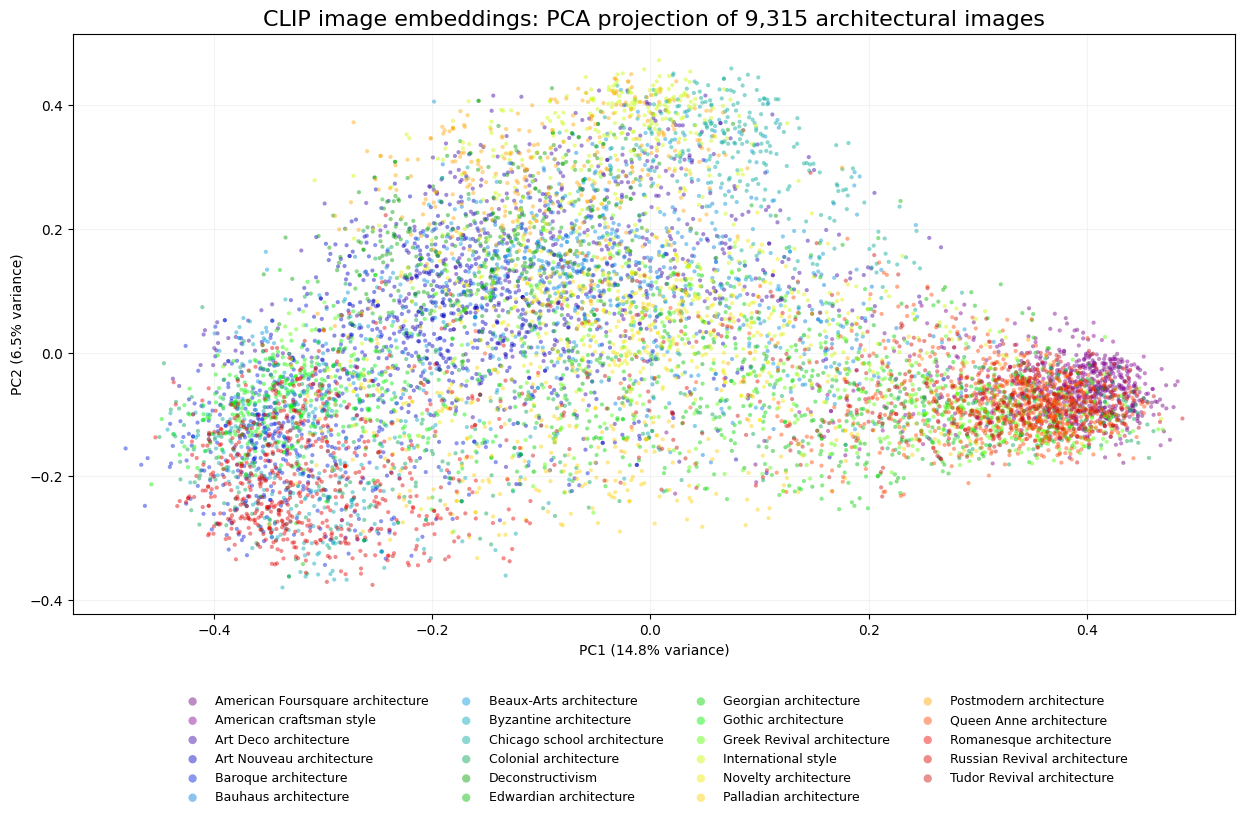

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Load saved CLIP embeddings and metadata
embeddings = embeddings_domain
metadata = metadata_domain


assert len(embeddings) == len(metadata)
assert embeddings.shape[1] == 512

# PCA using singular value decomposition
X = embeddings.astype(np.float64)
X_centered = X - X.mean(axis=0)

U, S, Vt = np.linalg.svd(
    X_centered, full_matrices=False
)

pca_coordinates = U[:, :2] * S[:2]

explained_variance = S**2 / np.sum(S**2)

print("PC1 variance:", explained_variance[0] * 100)
print("PC2 variance:", explained_variance[1] * 100)

# Architectural styles
styles = sorted(metadata["style"].unique())

# Distinct colors for 23 styles
colors = plt.cm.nipy_spectral(
    np.linspace(0.05, 0.95, len(styles))
)

fig, ax = plt.subplots(figsize=(15, 10))

for i, style in enumerate(styles):
    mask = metadata["style"].to_numpy() == style

    ax.scatter(
        pca_coordinates[mask, 0],
        pca_coordinates[mask, 1],
        s=9,
        alpha=0.45,
        color=colors[i],
        edgecolors="none",
        label=style
    )

ax.set_xlabel(
    f"PC1 ({explained_variance[0]*100:.1f}% variance)"
)
ax.set_ylabel(
    f"PC2 ({explained_variance[1]*100:.1f}% variance)"
)

ax.set_title(
    "CLIP image embeddings: PCA projection of "
    f"{len(metadata):,} architectural images",
    fontsize=16
)

ax.grid(alpha=0.15)

# Legend below the figure
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    fontsize=9,
    frameon=False,
    markerscale=2
)

plt.subplots_adjust(bottom=0.30)

plt.savefig(
    "clip_architecture_pca.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Define dataset-wide Precision@K for the 23-style domain

This function computes exact-label Precision@K across all query images for one or more values of K.

For each query:

1. cosine similarities to all candidate images are computed from normalized embeddings;
2. self-retrieval is suppressed;
3. the nearest candidates are ranked;
4. the retrieved labels are compared with the query label;
5. the fraction of same-label images among the top K is recorded.

The final metric is the mean of these per-query precision values.

### Meaning of P@1, P@5, and P@10

- **P@1** measures exact-label agreement for the single nearest neighbor.
- **P@5** measures the proportion of exact-label images among the five nearest neighbors.
- **P@10** does the same over the ten nearest neighbors.

As K grows, the metric asks whether the query's nominal style remains concentrated in a broader region of CLIP embedding space.

Again, these metrics intentionally assign zero relevance to all cross-label retrievals. 

In [13]:
def evaluate_precision_at_k(embeddings, metadata, ks=(1, 5, 10), batch_size=256):
    n = len(embeddings)
    styles = metadata["style"].to_numpy()

    precision_scores = {k: [] for k in ks}

    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)

        query_batch = embeddings[start:end]

        # Compare every query in this batch with every image
        similarities = query_batch @ embeddings.T

        # Prevent each image from retrieving itself
        rows = np.arange(end - start)
        cols = np.arange(start, end)
        similarities[rows, cols] = -np.inf

        # Rank from most similar to least similar
        ranked_indices = np.argsort(similarities, axis=1)[:, ::-1]

        for i, query_id in enumerate(range(start, end)):
            query_style = styles[query_id]

            for k in ks:
                top_k_indices = ranked_indices[i, :k]
                relevant = np.sum(styles[top_k_indices] == query_style)
                precision_scores[k].append(relevant / k)

        print(f"Processed {end}/{n}")

    mean_precision = {
        k: np.mean(precision_scores[k])
        for k in ks
    }

    return mean_precision

## Define a function that preserves every domain top-1 retrieval

Precision@K summarizes performance but discards the identity of individual retrievals. This function therefore creates a row-level record for every query in the 23-style domain.

For each query, the output preserves:

- query ID;
- query style;
- retrieved image ID;
- retrieved image style;
- CLIP similarity.

This table is essential for the later Paper-One analysis because architectural relevance must be attached to specific CLIP retrieval events.

### CLIP similarity versus architectural similarity

The `clip_similarity` stored here is an **image-level embedding similarity** between two particular images.

Later, an architectural style-similarity value is attached to the pair of style categories. Those are different quantities and should not be conflated:

- CLIP similarity asks how close two individual images are in CLIP space;
- architectural similarity asks how related two architectural style categories are according to the independent feature representation.


In [14]:
def get_clip_top1_results(embeddings, metadata, batch_size=256):
    n = len(embeddings)
    styles = metadata["style"].to_numpy()

    results = []

    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)

        query_batch = embeddings[start:end]

        # CLIP cosine similarities
        similarities = query_batch @ embeddings.T

        # Prevent an image from retrieving itself
        rows = np.arange(end - start)
        cols = np.arange(start, end)
        similarities[rows, cols] = -np.inf

        # We only need the best match
        top1_indices = np.argmax(similarities, axis=1)

        for i, query_id in enumerate(range(start, end)):
            retrieved_id = top1_indices[i]

            results.append({
                "query_id": query_id,
                "query_style": styles[query_id],
                "retrieved_id": retrieved_id,
                "retrieved_style": styles[retrieved_id],
                "clip_similarity": similarities[i, retrieved_id]
            })

        print(f"Processed {end}/{n}")

    return pd.DataFrame(results)

## Generate the complete 23-style top-1 retrieval table

The retrieval function is now applied to every image in the domain dataset.

The resulting `clip_top1` table contains one row per query image. This becomes a central data artifact for Paper One: it preserves CLIP's actual nearest-neighbor behavior before any architectural reinterpretation is introduced.

Inspecting the first rows is a simple sanity check that IDs, styles, and similarity values were recorded as intended.


In [15]:
clip_top1 = get_clip_top1_results(
    embeddings_domain,
    metadata_domain,
    batch_size=256
)

clip_top1.head()

Processed 256/9315
Processed 512/9315
Processed 768/9315
Processed 1024/9315
Processed 1280/9315
Processed 1536/9315
Processed 1792/9315
Processed 2048/9315
Processed 2304/9315
Processed 2560/9315
Processed 2816/9315
Processed 3072/9315
Processed 3328/9315
Processed 3584/9315
Processed 3840/9315
Processed 4096/9315
Processed 4352/9315
Processed 4608/9315
Processed 4864/9315
Processed 5120/9315
Processed 5376/9315
Processed 5632/9315
Processed 5888/9315
Processed 6144/9315
Processed 6400/9315
Processed 6656/9315
Processed 6912/9315
Processed 7168/9315
Processed 7424/9315
Processed 7680/9315
Processed 7936/9315
Processed 8192/9315
Processed 8448/9315
Processed 8704/9315
Processed 8960/9315
Processed 9216/9315
Processed 9315/9315


,query_id,query_style,retrieved_id,retrieved_style,clip_similarity
0,0,American Foursquare architecture,7514,Queen Anne architecture,0.723876
1,1,American Foursquare architecture,340,American Foursquare architecture,0.987062
2,2,American Foursquare architecture,7880,Queen Anne architecture,0.902493
3,3,American Foursquare architecture,7516,Queen Anne architecture,0.879560
4,4,American Foursquare architecture,5141,Georgian architecture,0.924064


## Save the domain top-1 retrieval results

The complete table is saved as `clip_top1_domain_results.csv`.

This file freezes the CLIP retrieval output used by the subsequent architectural-similarity analysis. Saving it is methodologically useful because later analyses can operate on the same retrieval events without repeatedly recomputing nearest neighbors.

In other words, CLIP's behavior is established first; the independent architectural measure is applied afterward.


In [16]:
clip_top1.to_csv(
    "clip_top1_domain_results.csv",
    index=False
)

print("Saved:", len(clip_top1), "CLIP top-1 retrieval results")

Saved: 9315 CLIP top-1 retrieval results


## Compute the final exact-label CLIP baseline for the 23-style domain

This cell evaluates P@1, P@5, and P@10 over the domain-restricted dataset.

These are the conventional baseline numbers to report for the 23-style experiment. They quantify exact agreement with the dataset's architectural-style labels and provide a reproducible reference for later interpretation.

A lower value at larger K does not necessarily imply that the broader neighborhood is architecturally poor. It means only that a smaller fraction of those neighbors carry the *identical nominal style label*.


In [17]:
domain_precision = evaluate_precision_at_k(
    embeddings_domain,
    metadata_domain,
    ks=(1, 5, 10),
    batch_size=256
)

domain_precision

Processed 256/9315
Processed 512/9315
Processed 768/9315
Processed 1024/9315
Processed 1280/9315
Processed 1536/9315
Processed 1792/9315
Processed 2048/9315
Processed 2304/9315
Processed 2560/9315
Processed 2816/9315
Processed 3072/9315
Processed 3328/9315
Processed 3584/9315
Processed 3840/9315
Processed 4096/9315
Processed 4352/9315
Processed 4608/9315
Processed 4864/9315
Processed 5120/9315
Processed 5376/9315
Processed 5632/9315
Processed 5888/9315
Processed 6144/9315
Processed 6400/9315
Processed 6656/9315
Processed 6912/9315
Processed 7168/9315
Processed 7424/9315
Processed 7680/9315
Processed 7936/9315
Processed 8192/9315
Processed 8448/9315
Processed 8704/9315
Processed 8960/9315
Processed 9216/9315
Processed 9315/9315


{1: np.float64(0.7352657004830918),
 5: np.float64(0.6461191626409019),
 10: np.float64(0.6064626945786367)}

## Save the domain baseline metrics

The three principal exact-label metrics are placed into a compact table and written to `clip_domain_baseline_metrics.csv`.

This creates a stable paper-ready baseline artifact.

The important methodological separation is now explicit:

**Baseline stage:** evaluate CLIP using strict dataset labels.

**Later stage:** investigate whether the cross-label retrievals rejected by that metric nevertheless contain systematic architectural structure.


In [18]:
domain_baseline = pd.DataFrame({
    "metric": ["P@1", "P@5", "P@10"],
    "value": [
        domain_precision[1],
        domain_precision[5],
        domain_precision[10]
    ]
})

domain_baseline.to_csv(
    "clip_domain_baseline_metrics.csv",
    index=False
)

domain_baseline

,metric,value
0,P@1,0.735266
1,P@5,0.646119
2,P@10,0.606463


## Independently reconstruct domain top-1 indices for verification and counting

This cell recomputes the nearest non-self image for every query in the 23-style domain and stores the resulting indices.

Although similar information already exists in `clip_top1`, this explicit reconstruction provides a straightforward array representation for final P@1 and same-style/cross-style counts.

As before, normalized embedding dot products implement cosine similarity, and self-matches are removed before selecting the maximum.


In [19]:
n_domain = len(embeddings_domain)
styles_domain = metadata_domain["style"].to_numpy()

domain_top1_indices = np.zeros(n_domain, dtype=int)

batch_size = 256

for start in range(0, n_domain, batch_size):
    end = min(start + batch_size, n_domain)

    query_batch = embeddings_domain[start:end]

    # Compare every query in the batch with all 9,315 domain images
    similarities = query_batch @ embeddings_domain.T

    # Prevent each query from retrieving itself
    rows = np.arange(end - start)
    cols = np.arange(start, end)
    similarities[rows, cols] = -np.inf

    # Rank results and keep only the #1 retrieved image
    ranked_indices = np.argsort(similarities, axis=1)[:, ::-1]
    domain_top1_indices[start:end] = ranked_indices[:, 0]

print("Finished.")
print("Number of top-1 retrievals:", len(domain_top1_indices))

Finished.
Number of top-1 retrievals: 9315


## Final domain summary: exact-label P@1 and mismatch counts

The retrieved indices are converted to style labels and compared with the query labels.

This produces the key counts underlying the 23-style top-1 baseline:

- exact-label P@1;
- number of same-style retrievals;
- number of cross-style retrievals.

The cross-style count defines the population examined in the next major phase of Paper One.

### Conceptual handoff to the architectural-relevance analysis

At this point, conventional evaluation has done everything it is supposed to do. It has identified which nearest-neighbor retrievals agree with the dataset label and which do not.

What it **cannot** determine is whether a different-label retrieval is architecturally close or architecturally implausible.

That is the central limitation addressed next by comparing these CLIP retrievals with the independently constructed hybrid architectural-similarity matrix.

The key research question becomes:

> **Are CLIP's cross-label nearest neighbors architecturally more related to their queries than we would expect by chance?**

That question—not a redefinition of the CLIP baseline—is what turns the nominal "errors" into the central analytical object of Paper One.


In [20]:
domain_predicted_styles = styles_domain[domain_top1_indices]

domain_p1 = np.mean(
    domain_predicted_styles == styles_domain
)

domain_cross_style_mask = (
    domain_predicted_styles != styles_domain
)

print("P@1:", domain_p1)
print("Same-style:", np.sum(~domain_cross_style_mask))
print("Cross-style:", np.sum(domain_cross_style_mask))

P@1: 0.7352657004830918
Same-style: 6849
Cross-style: 2466


# End of Notebook 03 — Baseline evaluation is now frozen

This notebook establishes and records CLIP's conventional retrieval performance before any architectural relevance measure is used to reinterpret the results.

The workflow has:

- evaluated nearest-neighbor retrieval over the original collection;
- examined top-1 style-confusion patterns;
- defined the practical 23-style architectural domain;
- recomputed P@1, P@5, and P@10 within that domain;
- preserved every domain top-1 retrieval and its CLIP similarity;
- separated exact-label matches from cross-label retrievals;
- saved the principal baseline artifacts for later analysis.

This separation is central to the experimental design of Paper One. CLIP retrieval behavior is generated independently first. Architectural similarity is introduced afterward as a distinct analytical representation.

Therefore, later agreement between CLIP's cross-label behavior and the architectural feature space is not built into this baseline by construction.

From here, the project can ask whether exact style-label disagreement **understates the architectural relevance already present in CLIP's embedding space**.
